In [1]:
# Setup Python

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import plotly.express as px

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
pd.set_option('display.max_columns', 30)
plt.rcParams.update({
    'figure.figsize': (10, 4.5),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
})

OUTPUT_DIR = Path('output')
FIG_DIR = OUTPUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

def rp(x):
    return 'Rp' + f'{x:,.0f}'.replace(',', '.')

In [2]:
# Data Kaggle FMCG For Portofolio

raw = pd.read_csv('FMCG_Kaggle.csv')

print(f"Jumlah Baris: {raw.shape[0]:,}")
print(f"Jumlah Kolom: {raw.shape[1]}")

print("\n--- INFO DATASET ---")
print(raw.info())

display(raw.head())

Jumlah Baris: 18,240
Jumlah Kolom: 27

--- INFO DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18240 entries, 0 to 18239
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             18240 non-null  object 
 1   Order_Date           18240 non-null  object 
 2   Year                 18240 non-null  int64  
 3   Quarter              18240 non-null  object 
 4   Month                18240 non-null  int64  
 5   Month_Name           18240 non-null  object 
 6   Region               18240 non-null  object 
 7   Country              18240 non-null  object 
 8   City                 18240 non-null  object 
 9   Sales_Person         18240 non-null  object 
 10  Customer_Type        18240 non-null  object 
 11  Sales_Channel        18240 non-null  object 
 12  Promotion_Type       18240 non-null  object 
 13  Product_Category     18240 non-null  object 
 14  Brand                18240

,Order_ID,Order_Date,Year,Quarter,Month,Month_Name,Region,Country,City,Sales_Person,Customer_Type,Sales_Channel,Promotion_Type,Product_Category,Brand,Product_Name,SKU,Units_Sold,Unit_Price_USD,Discount_Pct,Gross_Sales_USD,Marketing_Spend_USD,COGS_USD,Logistics_Cost_USD,Net_Revenue_USD,Profit_USD,Profit_Margin_Pct
0,FMCG-2025-000001,2025-09-26,2025,Q3,9,September,Oceania,Australia,Perth,Ethan Cole,B2C,Modern Trade,Seasonal Campaign,Personal Care,PureLiva,Shampoo Repair,PCR-PL-101,73,8.47,8.94,618.31,66.05,314.09,43.03,563.03,139.86,24.84
1,FMCG-2024-000002,2024-10-09,2024,Q4,10,October,Asia,India,Mumbai,Meera Nair,B2C,Online,Bundle Offer,Personal Care,BrightSmile,Toothpaste Mint,PCR-BS-301,99,2.89,9.86,286.11,35.26,123.79,23.89,257.90,74.96,29.07
2,FMCG-2024-000003,2024-07-06,2024,Q3,7,July,North America,USA,Los Angeles,Nina Booker,B2B,Distributor,Seasonal Campaign,Personal Care,FreshNest,Body Wash Citrus,PCR-FN-201,361,5.96,15.32,"2,151.56",171.46,"1,011.60",107.02,"1,821.94",531.86,29.19
3,FMCG-2024-000004,2024-05-25,2024,Q2,5,May,Europe,France,Paris,Oliver Kent,B2B,Wholesale,No Promo,Snacks,NutriBite,Protein Bar Peanut,SNK-NB-202,603,3.80,18.00,"2,291.40",118.39,"1,133.66",85.20,"1,878.95",541.70,28.83
4,FMCG-2023-000005,2023-08-10,2023,Q3,8,August,Europe,France,Lyon,Lucas Bennett,B2C,Modern Trade,Loyalty Cashback,Dairy & Breakfast,FarmJoy,Greek Yogurt Plain,DBF-FJ-202,113,3.18,12.46,359.34,34.82,157.70,23.02,314.57,99.03,31.48


In [3]:
cols_to_format = [
    "Unit_Price_USD", "Gross_Sales_USD", "Marketing_Spend_USD", 
    "COGS_USD", "Logistics_Cost_USD", "Net_Revenue_USD", "Profit_USD"
]

for col in cols_to_format:
    raw[col] = pd.to_numeric(raw[col], errors='coerce')
    raw[col] = raw[col].map("${:,.2f}".format)

raw["Discount_Pct"] = pd.to_numeric(raw["Discount_Pct"], errors='coerce').map("{:,.2f}%".format)
raw["Profit_Margin_Pct"] = pd.to_numeric(raw["Profit_Margin_Pct"], errors='coerce').map("{:,.2f}%".format)

display(raw.head())

,Order_ID,Order_Date,Year,Quarter,Month,Month_Name,Region,Country,City,Sales_Person,Customer_Type,Sales_Channel,Promotion_Type,Product_Category,Brand,Product_Name,SKU,Units_Sold,Unit_Price_USD,Discount_Pct,Gross_Sales_USD,Marketing_Spend_USD,COGS_USD,Logistics_Cost_USD,Net_Revenue_USD,Profit_USD,Profit_Margin_Pct
0,FMCG-2025-000001,2025-09-26,2025,Q3,9,September,Oceania,Australia,Perth,Ethan Cole,B2C,Modern Trade,Seasonal Campaign,Personal Care,PureLiva,Shampoo Repair,PCR-PL-101,73,$8.47,8.94%,$618.31,$66.05,$314.09,$43.03,$563.03,$139.86,24.84%
1,FMCG-2024-000002,2024-10-09,2024,Q4,10,October,Asia,India,Mumbai,Meera Nair,B2C,Online,Bundle Offer,Personal Care,BrightSmile,Toothpaste Mint,PCR-BS-301,99,$2.89,9.86%,$286.11,$35.26,$123.79,$23.89,$257.90,$74.96,29.07%
2,FMCG-2024-000003,2024-07-06,2024,Q3,7,July,North America,USA,Los Angeles,Nina Booker,B2B,Distributor,Seasonal Campaign,Personal Care,FreshNest,Body Wash Citrus,PCR-FN-201,361,$5.96,15.32%,"$2,151.56",$171.46,"$1,011.60",$107.02,"$1,821.94",$531.86,29.19%
3,FMCG-2024-000004,2024-05-25,2024,Q2,5,May,Europe,France,Paris,Oliver Kent,B2B,Wholesale,No Promo,Snacks,NutriBite,Protein Bar Peanut,SNK-NB-202,603,$3.80,18.00%,"$2,291.40",$118.39,"$1,133.66",$85.20,"$1,878.95",$541.70,28.83%
4,FMCG-2023-000005,2023-08-10,2023,Q3,8,August,Europe,France,Lyon,Lucas Bennett,B2C,Modern Trade,Loyalty Cashback,Dairy & Breakfast,FarmJoy,Greek Yogurt Plain,DBF-FJ-202,113,$3.18,12.46%,$359.34,$34.82,$157.70,$23.02,$314.57,$99.03,31.48%


In [4]:
# Data Cleaning (Log Kualitas Data)

def clean_retail_data(raw):
    df = raw.copy()
    log = []

    def step(name, before, after):
        log.append({
            'Langkah': name, 
            'Baris_Sebelum': before, 
            'Baris_Sesudah': after, 
            'Baris_Terdampak': before - after
        })

    # 1. Standarisasi Teks (Gunakan nama kolom yang sesuai dengan data Anda)
    cat_col = 'Product_Category' if 'Product_Category' in df.columns else 'Category'
    store_col = 'StoreID' if 'StoreID' in df.columns else 'Store_ID'
    
    for col in [cat_col, store_col, 'SKU']:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip()
    
    if cat_col in df.columns:
        df[cat_col] = df[cat_col].str.title()
    if store_col in df.columns:
        df[store_col] = df[store_col].str.upper()
        
    log.append({
        'Langkah': 'Standarisasi Teks', 
        'Baris_Sebelum': len(df), 
        'Baris_Sesudah': len(df), 
        'Baris_Terdampak': 0
    })

    # 2. Tipe Data Tanggal
    n = len(df)
    date_col = 'Order_Date' if 'Order_Date' in df.columns else 'InvoiceDate'
    df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
    df = df.dropna(subset=[date_col])
    step('Buang Tanggal Tidak Valid', n, len(df))

    # 3. Hapus Duplikat
    n = len(df)
    df = df.drop_duplicates()
    step('Buang Baris Duplikat', n, len(df))

    # 4. Pisahkan Transaksi Retur
    qty_col = 'Units_Sold' if 'Units_Sold' in df.columns else 'Quantity'
    if qty_col in df.columns:
        df[qty_col] = pd.to_numeric(df[qty_col], errors='coerce')
        returns = df[df[qty_col] < 0].copy()
        n = len(df)
        df = df[df[qty_col] > 0]
        step(f'Pisahkan Retur ({qty_col} < 0)', n, len(df))
    else:
        returns = pd.DataFrame()

    # 5. Filter Harga <= 0 (Pastikan membaca kolom Unit_Price_USD atau UnitPrice)
    price_col = 'Unit_Price_USD' if 'Unit_Price_USD' in df.columns else 'UnitPrice'
    if price_col in df.columns:
        n = len(df)
        # Bersihkan string dari simbol mata uang ($) jika ada sebelum diubah ke numerik
        if df[price_col].dtype == 'object':
            df[price_col] = df[price_col].astype(str).str.replace('$', '').str.replace(',', '').str.strip()
            
        df[price_col] = pd.to_numeric(df[price_col], errors='coerce')
        df = df[df[price_col] > 0]
        step('Buang Harga 0, Negatif, atau Kosong', n, len(df))

    # 6. Tangani Missing Value pada Customer
    cust_col = 'Customer_Type' if 'Customer_Type' in df.columns else 'CustomerID'
    if cust_col in df.columns:
        missing_cust = int(df[cust_col].isna().sum())
        df[cust_col] = df[cust_col].fillna('GUEST')
        log.append({
            'Langkah': f"Isi Missing {cust_col} dengan 'GUEST'", 
            'Baris_Sebelum': len(df), 
            'Baris_Sesudah': len(df), 
            'Baris_Terdampak': missing_cust
        })

    # 7. Buat Kolom Turunan
    df['Month_Period'] = df[date_col].dt.to_period('M').dt.to_timestamp()
    sales = df.sort_values(date_col).reset_index(drop=True)

    # Konversi log ke DataFrame untuk ditampilkan
    quality_log = pd.DataFrame(log)
    display(quality_log)
    print(f'Data bersih: {len(sales):,} baris | Retur terpisah: {len(returns):,} baris')
    
    return sales, returns, quality_log

# Jalankan ulang
sales, returns, quality_log = clean_retail_data(raw)
display(sales.head())

,Langkah,Baris_Sebelum,Baris_Sesudah,Baris_Terdampak
0,Standarisasi Teks,18240,18240,0
1,Buang Tanggal Tidak Valid,18240,18240,0
2,Buang Baris Duplikat,18240,18240,0
3,Pisahkan Retur (Units_Sold < 0),18240,18240,0
4,"Buang Harga 0, Negatif, atau Kosong",18240,18240,0
5,Isi Missing Customer_Type dengan 'GUEST',18240,18240,0


Data bersih: 18,240 baris | Retur terpisah: 0 baris


,Order_ID,Order_Date,Year,Quarter,Month,Month_Name,Region,Country,City,Sales_Person,Customer_Type,Sales_Channel,Promotion_Type,Product_Category,Brand,Product_Name,SKU,Units_Sold,Unit_Price_USD,Discount_Pct,Gross_Sales_USD,Marketing_Spend_USD,COGS_USD,Logistics_Cost_USD,Net_Revenue_USD,Profit_USD,Profit_Margin_Pct,Month_Period
0,FMCG-2023-005244,2023-01-01,2023,Q1,1,January,Europe,UK,London,Lucas Bennett,B2B,Modern Trade,Seasonal Campaign,Household,SparkShield,Surface Cleaner,HHD-SS-201,89,5.97,19.73%,$531.33,$59.40,$215.18,$36.45,$426.50,$115.47,27.07%,2023-01-01
1,FMCG-2023-017472,2023-01-01,2023,Q1,1,January,Asia,Thailand,Bangkok,Diya Kapoor,B2C,Modern Trade,No Promo,Personal Care,FreshNest,Hand Soap Gentle,PCR-FN-202,22,2.69,2.77%,$59.18,$6.14,$30.88,$3.63,$57.54,$16.89,29.35%,2023-01-01
2,FMCG-2023-006588,2023-01-01,2023,Q1,1,January,Europe,Spain,Valencia,Sofia Mercer,B2B,Modern Trade,Seasonal Campaign,Dairy & Breakfast,PantryPeak,Peanut Butter Creamy,DBF-PP-301,294,6.27,18.17%,"$1,843.38",$158.92,$882.56,$100.48,"$1,508.44",$366.48,24.30%,2023-01-01
3,FMCG-2023-011561,2023-01-01,2023,Q1,1,January,Europe,Germany,Berlin,Hugo Martin,B2B,Modern Trade,Flash Discount,Snacks,NutriBite,Protein Bar Cocoa,SNK-NB-201,260,3.67,21.63%,$954.20,$128.43,$431.12,$49.75,$747.81,$138.51,18.52%,2023-01-01
4,FMCG-2023-002026,2023-01-01,2023,Q1,1,January,Europe,UK,Manchester,Amelia Rhodes,B2B,Distributor,Bundle Offer,Personal Care,PureLiva,Shampoo Repair,PCR-PL-101,596,7.10,16.75%,"$4,231.60",$331.27,"$1,953.78",$208.02,"$3,522.81","$1,029.74",29.23%,2023-01-01


In [5]:
# KPI Executie Summary

numeric_cols = ['Net_Revenue_USD', 'Profit_USD', 'Units_Sold']
for col in numeric_cols:
    if col in sales.columns:
        # Jika ada simbol $ atau koma, bersihkan dulu lalu ubah ke float/int
        if sales[col].dtype == 'object':
            sales[col] = sales[col].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).str.strip()
        sales[col] = pd.to_numeric(sales[col], errors='coerce').fillna(0)

# 2. Perhitungan KPI
total_rev = sales['Net_Revenue_USD'].sum()
gross_profit = sales['Profit_USD'].sum()
gross_margin = gross_profit / total_rev if total_rev > 0 else 0
n_orders = sales['Order_ID'].nunique() if 'Order_ID' in sales.columns else len(sales)
total_units = sales['Units_Sold'].sum()

# Menghitung Pelanggan Unik / Sales Person
n_customers = sales['Sales_Person'].nunique() if 'Sales_Person' in sales.columns else 0

# Menghitung Return Rate (jika ada data returns)
if 'returns' in locals() and len(returns) > 0:
    # Pastikan units sold di returns juga numerik
    returns['Units_Sold'] = pd.to_numeric(returns['Units_Sold'], errors='coerce').fillna(0)
    return_units = returns['Units_Sold'].abs().sum()
    return_rate = return_units / (total_units + return_units) if (total_units + return_units) > 0 else 0
else:
    return_rate = 0.0

# Fungsi format mata uang USD ($)
def usd(val):
    return f"${val:,.2f}"

# Membuat DataFrame KPI
kpi = pd.DataFrame({
    'KPI': [
        'Total Revenue', 'Gross Profit', 'Gross Margin', 
        'Jumlah Order', 'AOV (Average Order Value)', 
        'Basket Size', 'Active Sales Persons / Customers', 'Return Rate'
    ],
    'Nilai': [
        usd(total_rev), 
        usd(gross_profit), 
        f'{gross_margin:.1%}', 
        f'{n_orders:,}', 
        usd(total_rev / n_orders) if n_orders > 0 else "$0.00", 
        f'{total_units / n_orders:.2f} unit/order' if n_orders > 0 else "0.00 unit/order", 
        f'{n_customers:,}', 
        f'{return_rate:.2%}'
    ]
})

display(kpi)

,KPI,Nilai
0,Total Revenue,"$14,449,920.00"
1,Gross Profit,"$3,308,965.31"
2,Gross Margin,22.9%
3,Jumlah Order,"18,240"
4,AOV (Average Order Value),$792.21
5,Basket Size,212.91 unit/order
6,Active Sales Persons / Customers,36
7,Return Rate,0.00%


In [6]:
cols_to_clean = [
    'Net_Revenue_USD', 'Profit_USD', 'Marketing_Spend_USD', 
    'Logistics_Cost_USD', 'Gross_Sales_USD', 'Discount_Pct', 'COGS_USD'
]

for col in cols_to_clean:
    if col in sales.columns:
        if sales[col].dtype == 'object':
            sales[col] = sales[col].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).str.replace('%', '', regex=False).str.strip()
        sales[col] = pd.to_numeric(sales[col], errors='coerce').fillna(0)

# 2. Perhitungan Advanced KPI setelah dipastikan semuanya angka
total_rev = sales['Net_Revenue_USD'].sum()
total_gross = sales['Gross_Sales_USD'].sum() if 'Gross_Sales_USD' in sales.columns else total_rev
total_profit = sales['Profit_USD'].sum()
total_marketing = sales['Marketing_Spend_USD'].sum() if 'Marketing_Spend_USD' in sales.columns else 0
total_logistics = sales['Logistics_Cost_USD'].sum() if 'Logistics_Cost_USD' in sales.columns else 0
cogs_total = sales['COGS_USD'].sum() if 'COGS_USD' in sales.columns else 0

# --- Rumus KPI Lanjutan ---
marketing_roi = (total_profit / total_marketing) * 100 if total_marketing > 0 else 0
logistics_ratio = (total_logistics / total_rev) * 100 if total_rev > 0 else 0
avg_discount = sales['Discount_Pct'].mean() if 'Discount_Pct' in sales.columns else 0
cost_efficiency = ((cogs_total + total_logistics) / total_rev) * 100 if total_rev > 0 else 0

# Fungsi format mata uang USD
def usd(val):
    return f"${val:,.2f}"

# 3. Membuat DataFrame Advanced KPI
advanced_kpi = pd.DataFrame({
    'Advanced KPI': [
        'Total Marketing Spend', 
        'Total Logistics Cost', 
        'Marketing ROI', 
        'Logistics Cost Ratio', 
        'Average Discount Given', 
        'Total Operating Cost Ratio (COGS + Logistics)'
    ],
    'Nilai': [
        usd(total_marketing), 
        usd(total_logistics), 
        f'{marketing_roi:,.2f}%', 
        f'{logistics_ratio:.2f}%', 
        f'{avg_discount:.2f}%', 
        f'{cost_efficiency:.2f}%'
    ]
})

display(advanced_kpi)

,Advanced KPI,Nilai
0,Total Marketing Spend,"$1,563,932.03"
1,Total Logistics Cost,"$985,539.83"
2,Marketing ROI,211.58%
3,Logistics Cost Ratio,6.82%
4,Average Discount Given,12.94%
5,Total Operating Cost Ratio (COGS + Logistics),66.28%


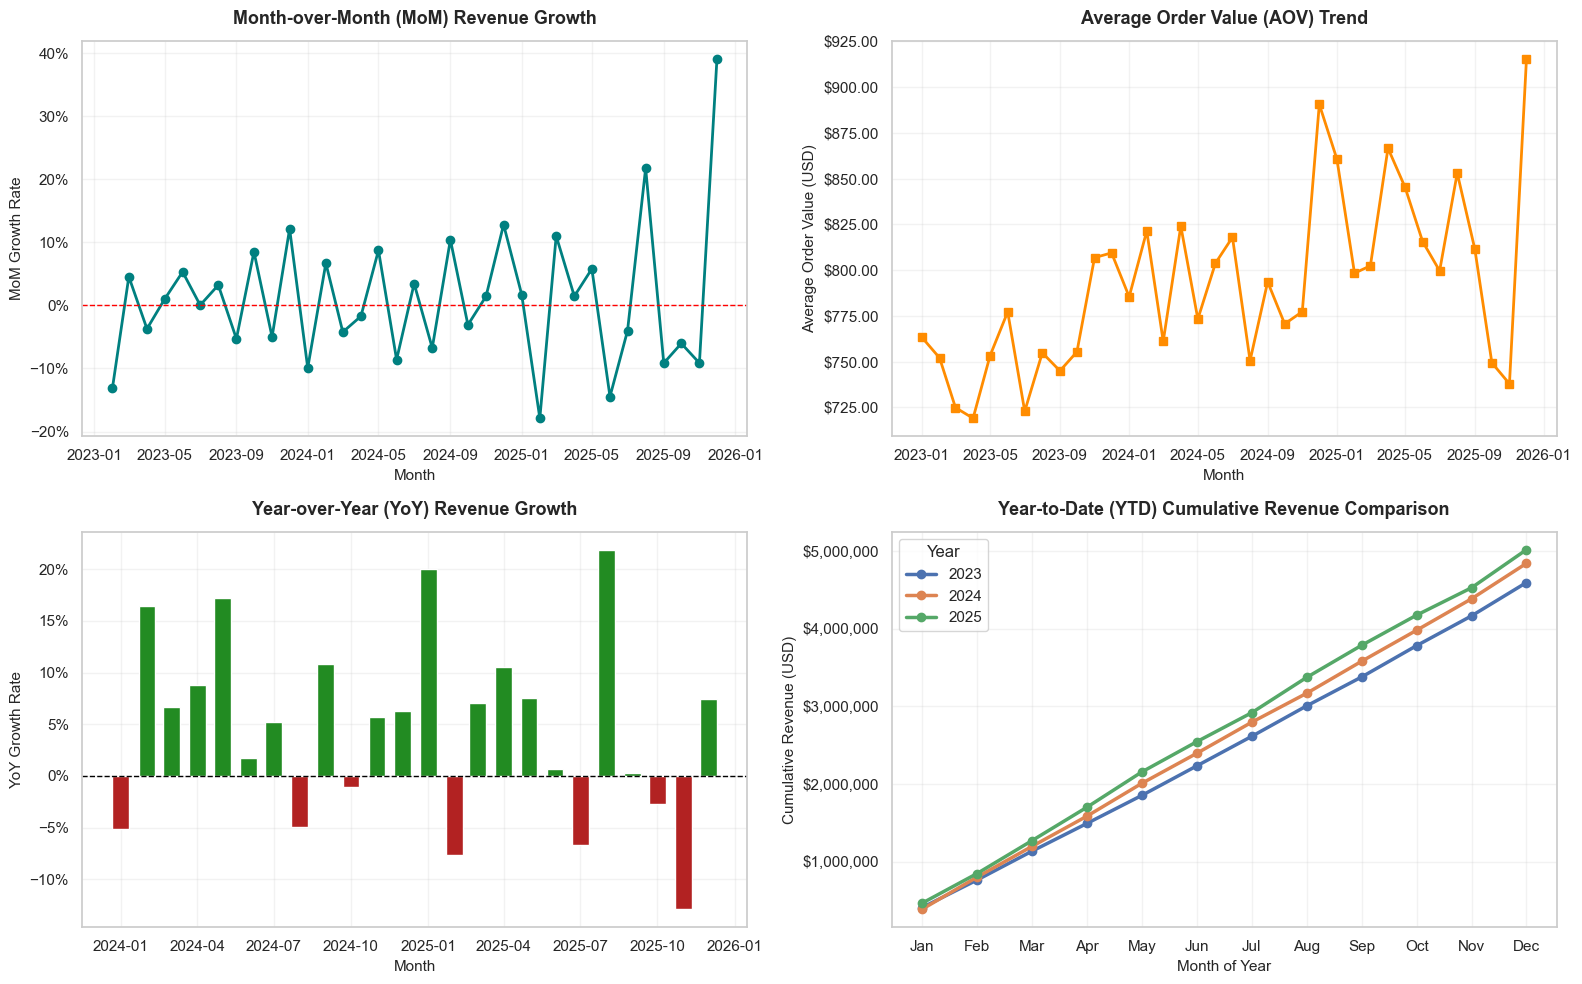

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Pastikan tipe data benar dan bersih
sales['Order_Date'] = pd.to_datetime(sales['Order_Date'])
sales['Net_Revenue_USD'] = pd.to_numeric(
    sales['Net_Revenue_USD'].astype(str).str.replace('$', '', regex=False).str.replace(',', ''), 
    errors='coerce'
).fillna(0)

# Agregasi Bulanan (Revenue & Total Transaksi/Order)
monthly_fin = sales.groupby(sales['Order_Date'].dt.to_period('M')).agg(
    Revenue=('Net_Revenue_USD', 'sum'),
    Total_Orders=('Order_ID', 'count') # Menghitung jumlah transaksi
).reset_index()

monthly_fin['Month'] = monthly_fin['Order_Date'].dt.to_timestamp()
monthly_fin = monthly_fin.sort_values('Month').reset_index(drop=True)

# 3. Hitung Metrik Keuangan Utama
# A. MoM Growth (%)
monthly_fin['MoM_pct'] = monthly_fin['Revenue'].pct_change()

# B. AOV (Average Order Value) = Total Revenue / Total Orders pada bulan tersebut
monthly_fin['AOV'] = monthly_fin['Revenue'] / monthly_fin['Total_Orders']

# C. YoY Growth (%): Bandingkan dengan 12 bulan lalu
monthly_fin['YoY_pct'] = monthly_fin['Revenue'].pct_change(periods=12)

# D. YTD (Year-to-Date): Akumulasi pendapatan dari awal tahun hingga bulan berjalan
monthly_fin['Year'] = monthly_fin['Month'].dt.year
monthly_fin['YTD_Revenue'] = monthly_fin.groupby('Year')['Revenue'].cumsum()

# Tambahkan kolom angka bulan untuk keperluan pivot YTD
monthly_fin['Month_Num'] = monthly_fin['Month'].dt.month



sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# MoM Growth Trend
axes[0, 0].plot(monthly_fin['Month'], monthly_fin['MoM_pct'], marker='o', color='teal', linewidth=2)
axes[0, 0].axhline(0, color='red', linestyle='--', linewidth=1)
axes[0, 0].set_title('Month-over-Month (MoM) Revenue Growth', fontsize=13, fontweight='bold', pad=12)
axes[0, 0].set_xlabel('Month', fontsize=11)
axes[0, 0].set_ylabel('MoM Growth Rate', fontsize=11)
axes[0, 0].yaxis.set_major_formatter('{x:.0%}')


# AOV (Average Order Value) Trend
axes[0, 1].plot(monthly_fin['Month'], monthly_fin['AOV'], marker='s', color='darkorange', linewidth=2)
axes[0, 1].set_title('Average Order Value (AOV) Trend', fontsize=13, fontweight='bold', pad=12)
axes[0, 1].set_xlabel('Month', fontsize=11)
axes[0, 1].set_ylabel('Average Order Value (USD)', fontsize=11)
axes[0, 1].yaxis.set_major_formatter('${x:,.2f}')


# YoY Growth Rate=
yoy_colors = ['forestgreen' if x >= 0 else 'firebrick' for x in monthly_fin['YoY_pct'].fillna(0)]
axes[1, 0].bar(monthly_fin['Month'], monthly_fin['YoY_pct'], color=yoy_colors, width=20)
axes[1, 0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1, 0].set_title('Year-over-Year (YoY) Revenue Growth', fontsize=13, fontweight='bold', pad=12)
axes[1, 0].set_xlabel('Month', fontsize=11)
axes[1, 0].set_ylabel('YoY Growth Rate', fontsize=11)
axes[1, 0].yaxis.set_major_formatter('{x:.0%}')


# YTD Cumulative Revenue by Year
pivot_ytd = monthly_fin.pivot(
    index='Month_Num', 
    columns='Year', 
    values='YTD_Revenue'
)

month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

for yr in pivot_ytd.columns:
    axes[1, 1].plot(pivot_ytd.index, pivot_ytd[yr], marker='o', linewidth=2.5, label=str(yr))

axes[1, 1].set_title('Year-to-Date (YTD) Cumulative Revenue Comparison', fontsize=13, fontweight='bold', pad=12)
axes[1, 1].set_xlabel('Month of Year', fontsize=11)
axes[1, 1].set_ylabel('Cumulative Revenue (USD)', fontsize=11)
axes[1, 1].set_xticks(range(1, 13))
axes[1, 1].set_xticklabels(month_labels)
axes[1, 1].yaxis.set_major_formatter('${x:,.0f}')
axes[1, 1].legend(title='Year')


plt.tight_layout()
plt.show()

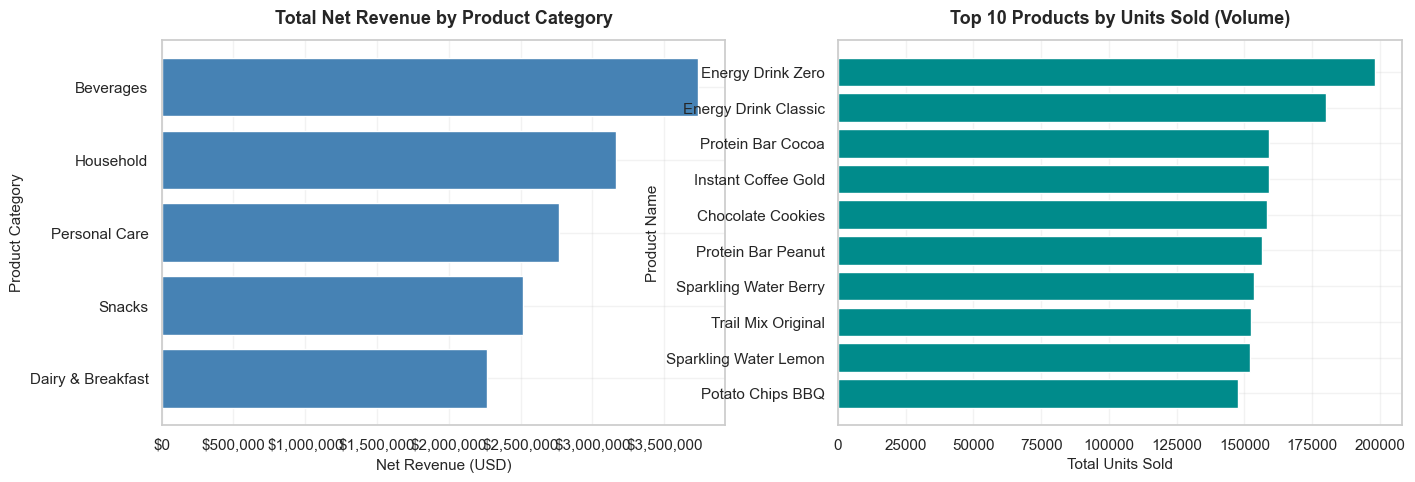

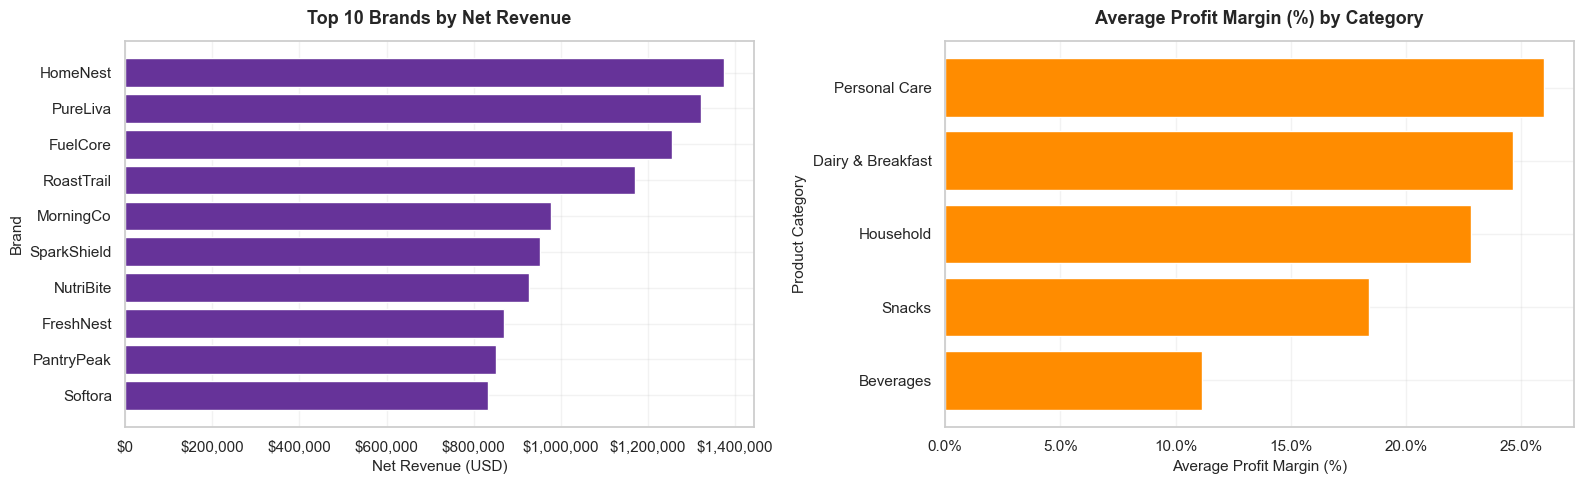

In [46]:
# Product & brand Performance

cols_product = ['Net_Revenue_USD', 'Profit_USD', 'Units_Sold', 'Unit_Price_USD']
for col in cols_product:
    if col in sales.columns:
        sales[col] = pd.to_numeric(
            sales[col].astype(str).str.replace('$', '', regex=False).str.replace(',', ''), 
            errors='coerce'
        ).fillna(0)

sns.set_theme(style="whitegrid")
fig1, axes1 = plt.subplots(1, 2, figsize=(16, 5))

# Product Category
cat_rev = sales.groupby('Product_Category')['Net_Revenue_USD'].sum().reset_index().sort_values(by='Net_Revenue_USD', ascending=True)

axes1[0].barh(cat_rev['Product_Category'], cat_rev['Net_Revenue_USD'], color='steelblue')
axes1[0].set_title('Total Net Revenue by Product Category', fontsize=13, fontweight='bold', pad=12)
axes1[0].set_xlabel('Net Revenue (USD)', fontsize=11)
axes1[0].set_ylabel('Product Category', fontsize=11)
axes1[0].xaxis.set_major_formatter('${x:,.0f}')

# Top Products
top_units = sales.groupby('Product_Name')['Units_Sold'].sum().reset_index().sort_values(by='Units_Sold', ascending=True).tail(10)

axes1[1].barh(top_units['Product_Name'], top_units['Units_Sold'], color='darkcyan')
axes1[1].set_title('Top 10 Products by Units Sold (Volume)', fontsize=13, fontweight='bold', pad=12)
axes1[1].set_xlabel('Total Units Sold', fontsize=11)
axes1[1].set_ylabel('Product Name', fontsize=11)

fig2, axes2 = plt.subplots(1, 2, figsize=(16, 5))

# Top Brands
brand_rev = sales.groupby('Brand')['Net_Revenue_USD'].sum().reset_index().sort_values(by='Net_Revenue_USD', ascending=True).tail(10)

axes2[0].barh(brand_rev['Brand'], brand_rev['Net_Revenue_USD'], color='rebeccapurple')
axes2[0].set_title('Top 10 Brands by Net Revenue', fontsize=13, fontweight='bold', pad=12)
axes2[0].set_xlabel('Net Revenue (USD)', fontsize=11)
axes2[0].set_ylabel('Brand', fontsize=11)
axes2[0].xaxis.set_major_formatter('${x:,.0f}')

# Grafik Average Profit Margin (%) By Category
if sales['Profit_Margin_Pct'].dtype == object:
    sales['Profit_Margin_Pct_Clean'] = sales['Profit_Margin_Pct'].astype(str).str.replace('%', '', regex=False).astype(float)
else:
    sales['Profit_Margin_Pct_Clean'] = sales['Profit_Margin_Pct'] * 100 # jika format desimal 0.27

cat_margin = sales.groupby('Product_Category')['Profit_Margin_Pct_Clean'].mean().reset_index().sort_values(by='Profit_Margin_Pct_Clean', ascending=True)

axes2[1].barh(cat_margin['Product_Category'], cat_margin['Profit_Margin_Pct_Clean'], color='darkorange')
axes2[1].set_title('Average Profit Margin (%) by Category', fontsize=13, fontweight='bold', pad=12)
axes2[1].set_xlabel('Average Profit Margin (%)', fontsize=11)
axes2[1].set_ylabel('Product Category', fontsize=11)
axes2[1].xaxis.set_major_formatter('{x:.1f}%')

plt.tight_layout()
plt.show()

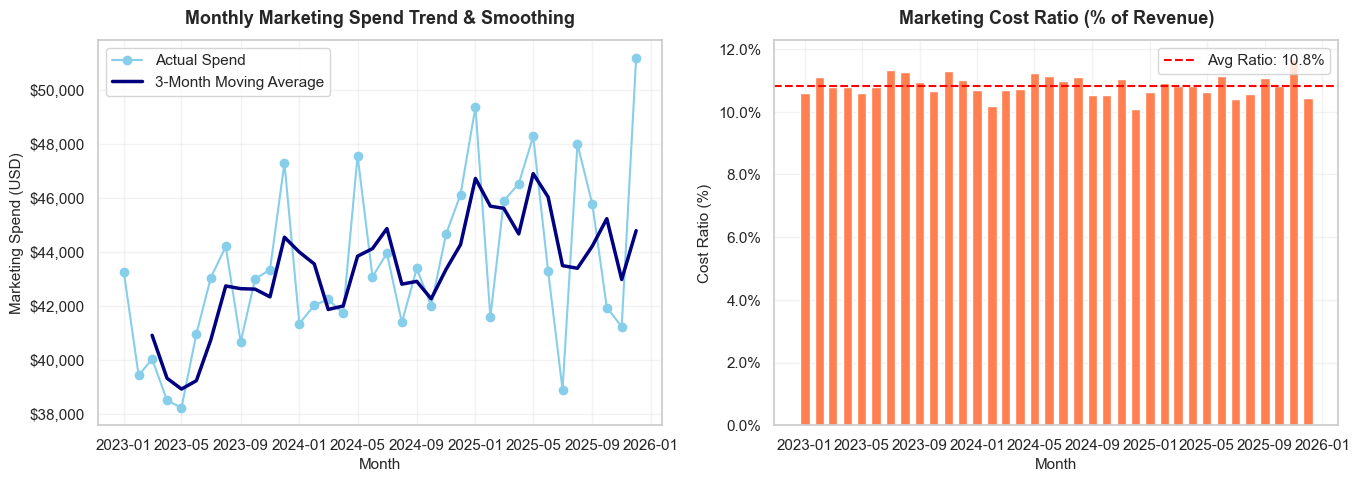

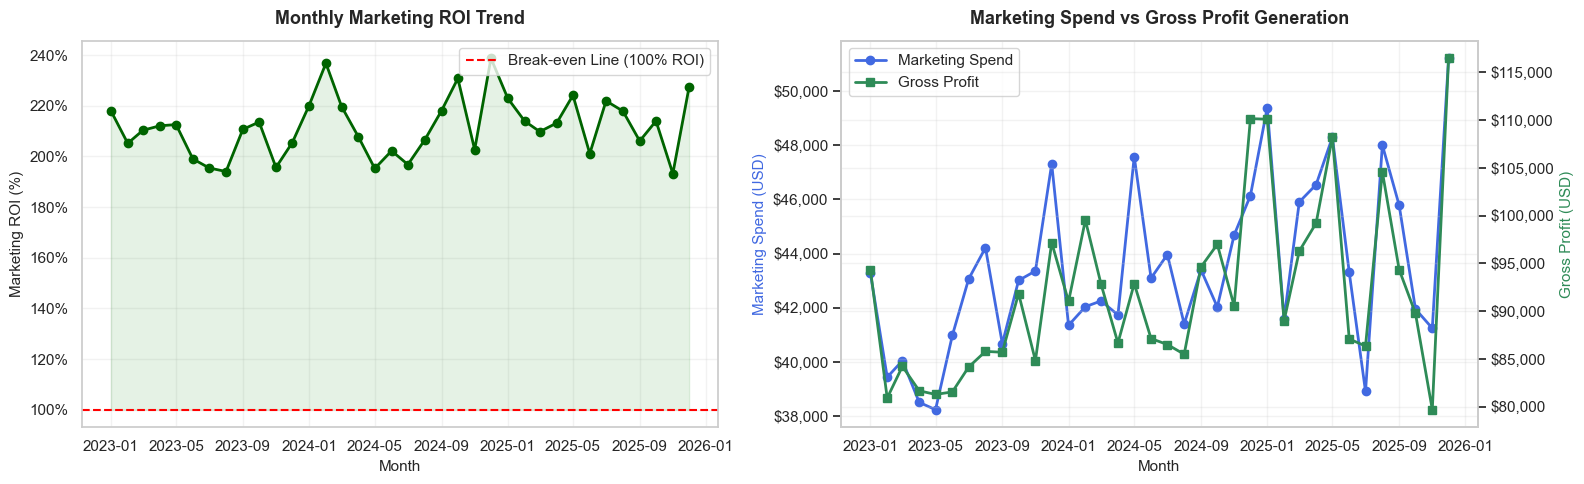

In [45]:
# Marketing Perfomance

cols_marketing = ['Marketing_Spend_USD', 'Net_Revenue_USD', 'Profit_USD']
for col in cols_marketing:
    if col in sales.columns:
        sales[col] = pd.to_numeric(
            sales[col].astype(str).str.replace('$', '', regex=False).str.replace(',', ''), 
            errors='coerce'
        ).fillna(0)

sales['Order_Date'] = pd.to_datetime(sales['Order_Date'])

monthly_mkt = sales.groupby(sales['Order_Date'].dt.to_period('M')).agg(
    Marketing_Spend=('Marketing_Spend_USD', 'sum'),
    Revenue=('Net_Revenue_USD', 'sum'),
    Gross_Profit=('Profit_USD', 'sum')
).reset_index()

monthly_mkt['Month'] = monthly_mkt['Order_Date'].dt.to_timestamp()
monthly_mkt = monthly_mkt.sort_values('Month').reset_index(drop=True)

monthly_mkt['Marketing_Cost_Ratio'] = (monthly_mkt['Marketing_Spend'] / monthly_mkt['Revenue']) * 100
monthly_mkt['Marketing_ROI'] = (monthly_mkt['Gross_Profit'] / monthly_mkt['Marketing_Spend']) * 100
monthly_mkt['Spend_MA3'] = monthly_mkt['Marketing_Spend'].rolling(window=3).mean()

sns.set_theme(style="whitegrid")
fig1, axes1 = plt.subplots(1, 2, figsize=(16, 5))

# Grafik Monthly Marketing Spend & Smoothing (Trend)
axes1[0].plot(monthly_mkt['Month'], monthly_mkt['Marketing_Spend'], marker='o', color='skyblue', label='Actual Spend', linewidth=1.5)
axes1[0].plot(monthly_mkt['Month'], monthly_mkt['Spend_MA3'], color='navy', label='3-Month Moving Average', linewidth=2.5)
axes1[0].set_title('Monthly Marketing Spend Trend & Smoothing', fontsize=13, fontweight='bold', pad=12)
axes1[0].set_xlabel('Month', fontsize=11)
axes1[0].set_ylabel('Marketing Spend (USD)', fontsize=11)
axes1[0].yaxis.set_major_formatter('${x:,.0f}')
axes1[0].legend(loc='upper left')

# Grafik Marketing Cost Ratio (Persentase Spend terhadap Revenue)
axes1[1].bar(monthly_mkt['Month'], monthly_mkt['Marketing_Cost_Ratio'], color='coral', width=20)
axes1[1].axhline(monthly_mkt['Marketing_Cost_Ratio'].mean(), color='red', linestyle='--', linewidth=1.5, label=f'Avg Ratio: {monthly_mkt["Marketing_Cost_Ratio"].mean():.1f}%')
axes1[1].set_title('Marketing Cost Ratio (% of Revenue)', fontsize=13, fontweight='bold', pad=12)
axes1[1].set_xlabel('Month', fontsize=11)
axes1[1].set_ylabel('Cost Ratio (%)', fontsize=11)
axes1[1].yaxis.set_major_formatter('{x:.1f}%')
axes1[1].legend(loc='upper right')

fig2, axes2 = plt.subplots(1, 2, figsize=(16, 5))

# Grafik Marketing ROI Trend (Efektivitas Keuntungan dari Iklan)
axes2[0].plot(monthly_mkt['Month'], monthly_mkt['Marketing_ROI'], marker='o', color='darkgreen', linewidth=2)
axes2[0].fill_between(monthly_mkt['Month'], monthly_mkt['Marketing_ROI'], 100, color='green', alpha=0.1)
axes2[0].axhline(100, color='red', linestyle='--', linewidth=1.5, label='Break-even Line (100% ROI)')
axes2[0].set_title('Monthly Marketing ROI Trend', fontsize=13, fontweight='bold', pad=12)
axes2[0].set_xlabel('Month', fontsize=11)
axes2[0].set_ylabel('Marketing ROI (%)', fontsize=11)
axes2[0].yaxis.set_major_formatter('{x:.0f}%')
axes2[0].legend(loc='upper right')

# Grafik Perbandingan Langsung Marketing Spend vs Gross Profit
ax3 = axes2[1]
ax4 = ax3.twinx()

line1 = ax3.plot(monthly_mkt['Month'], monthly_mkt['Marketing_Spend'], color='royalblue', marker='o', label='Marketing Spend', linewidth=2)
line2 = ax4.plot(monthly_mkt['Month'], monthly_mkt['Gross_Profit'], color='seagreen', marker='s', label='Gross Profit', linewidth=2)

ax3.set_title('Marketing Spend vs Gross Profit Generation', fontsize=13, fontweight='bold', pad=12)
ax3.set_xlabel('Month', fontsize=11)
ax3.set_ylabel('Marketing Spend (USD)', fontsize=11, color='royalblue')
ax4.set_ylabel('Gross Profit (USD)', fontsize=11, color='seagreen')

ax3.yaxis.set_major_formatter('${x:,.0f}')
ax4.yaxis.set_major_formatter('${x:,.0f}')

# Menggabungkan legend dari dua axis berbeda
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax3.legend(lines, labels, loc='upper left')

plt.tight_layout()
plt.show()

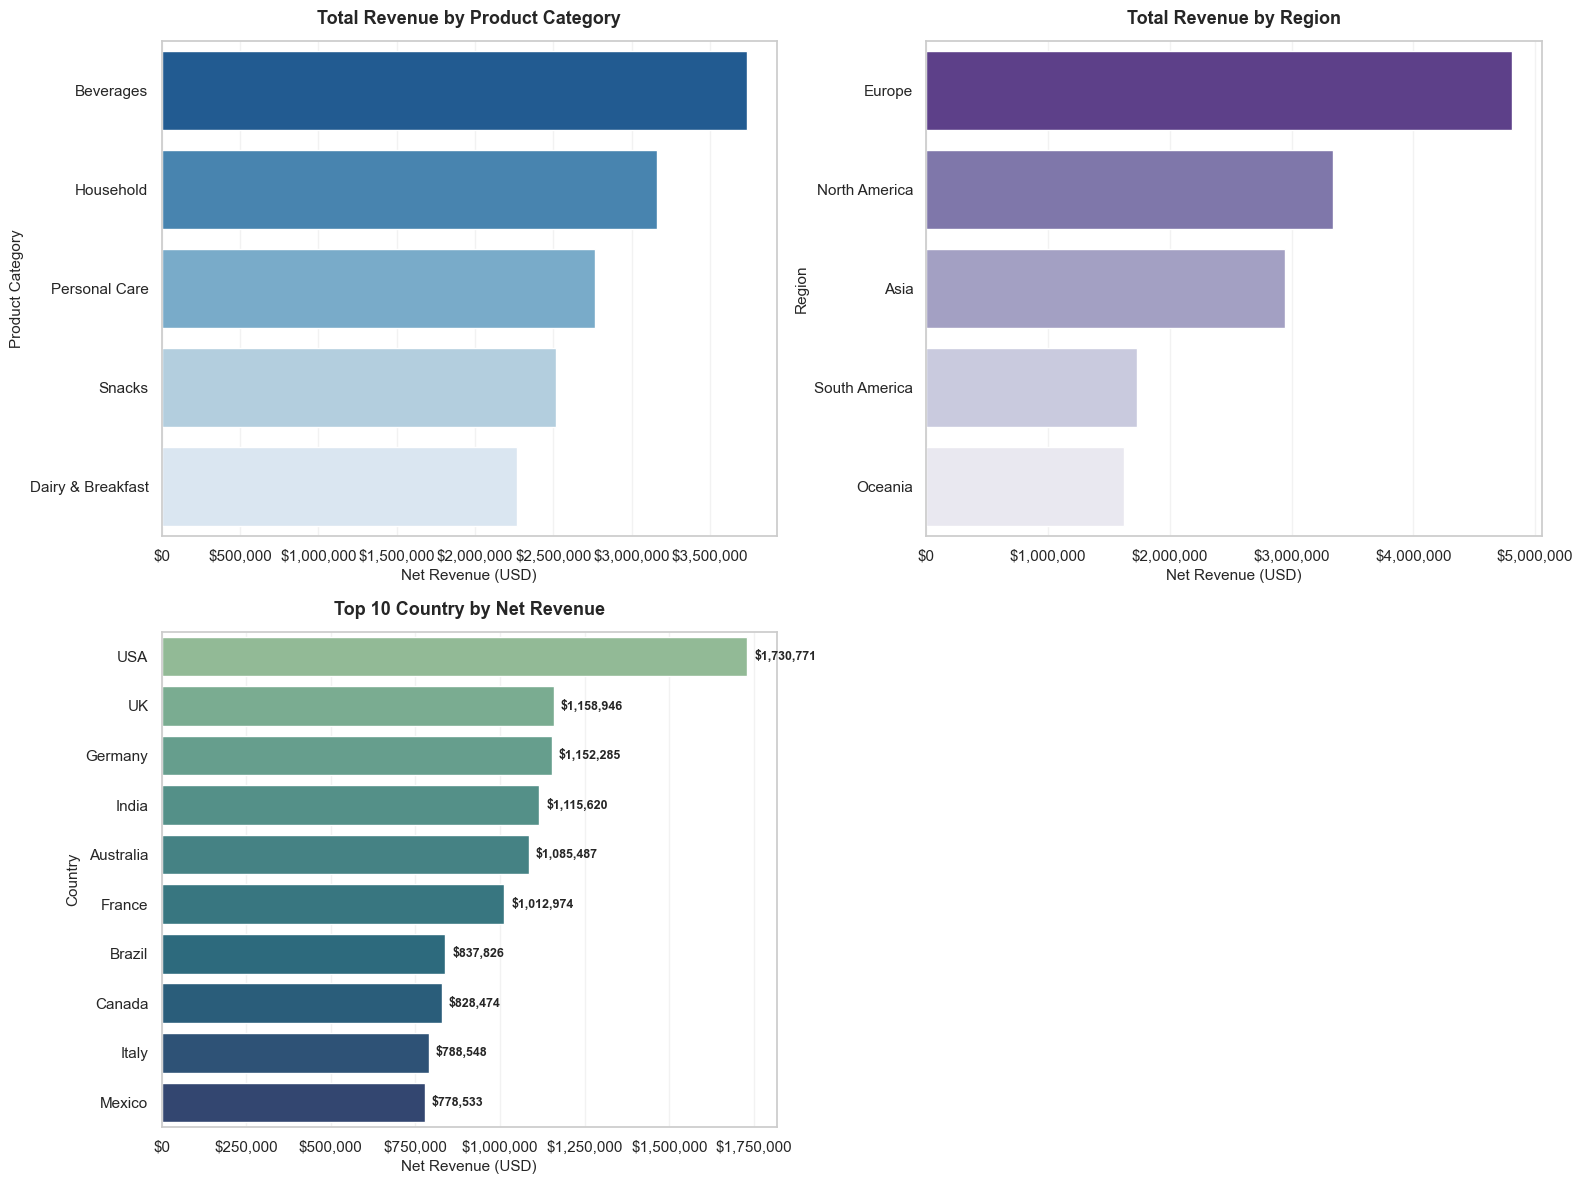

In [44]:
# Sales Performance

sales['Net_Revenue_USD'] = pd.to_numeric(sales['Net_Revenue_USD'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
sales['Profit_USD'] = pd.to_numeric(sales['Profit_USD'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')

cat_df = sales.groupby('Product_Category')['Net_Revenue_USD'].sum().reset_index().sort_values(by='Net_Revenue_USD', ascending=False)
region_df = sales.groupby('Region')['Net_Revenue_USD'].sum().reset_index().sort_values(by='Net_Revenue_USD', ascending=False) if 'Region' in sales.columns else pd.DataFrame()
top_sales = sales.groupby('Country').agg(Total_Revenue=('Net_Revenue_USD', 'sum')).reset_index().sort_values(by='Total_Revenue', ascending=False).head(10)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Product Category
sns.barplot(
    data=cat_df, 
    x='Net_Revenue_USD', 
    y='Product_Category', 
    palette='Blues_r', 
    ax=axes[0, 0]
)
axes[0, 0].set_title('Total Revenue by Product Category', fontsize=13, fontweight='bold', pad=12)
axes[0, 0].set_xlabel('Net Revenue (USD)', fontsize=11)
axes[0, 0].set_ylabel('Product Category', fontsize=11)
axes[0, 0].xaxis.set_major_formatter('${x:,.0f}')


# Wilayah (Region)
if not region_df.empty:
    sns.barplot(
        data=region_df, 
        x='Net_Revenue_USD', 
        y='Region', 
        palette='Purples_r', 
        ax=axes[0, 1]
    )
    axes[0, 1].set_title('Total Revenue by Region', fontsize=13, fontweight='bold', pad=12)
    axes[0, 1].set_xlabel('Net Revenue (USD)', fontsize=11)
    axes[0, 1].set_ylabel('Region', fontsize=11)
    axes[0, 1].xaxis.set_major_formatter('${x:,.0f}')


# Top Country
sns.barplot(
    data=top_sales, 
    x='Total_Revenue', 
    y='Country', 
    palette='crest', 
    ax=axes[1, 0]
)
axes[1, 0].set_title('Top 10 Country by Net Revenue', fontsize=13, fontweight='bold', pad=12)
axes[1, 0].set_xlabel('Net Revenue (USD)', fontsize=11)
axes[1, 0].set_ylabel('Country', fontsize=11)
axes[1, 0].xaxis.set_major_formatter('${x:,.0f}')

for p in axes[1, 0].patches:
    width = p.get_width()
    if width > 0:
        axes[1, 0].annotate(
            f"${width:,.0f}",
            xy=(width, p.get_y() + p.get_height() / 2),
            xytext=(5, 0),
            textcoords="offset points",
            ha='left', va='center',
            fontsize=9, fontweight='semibold'
        )

axes[1, 1].set_visible(False) 

plt.tight_layout()
plt.show()

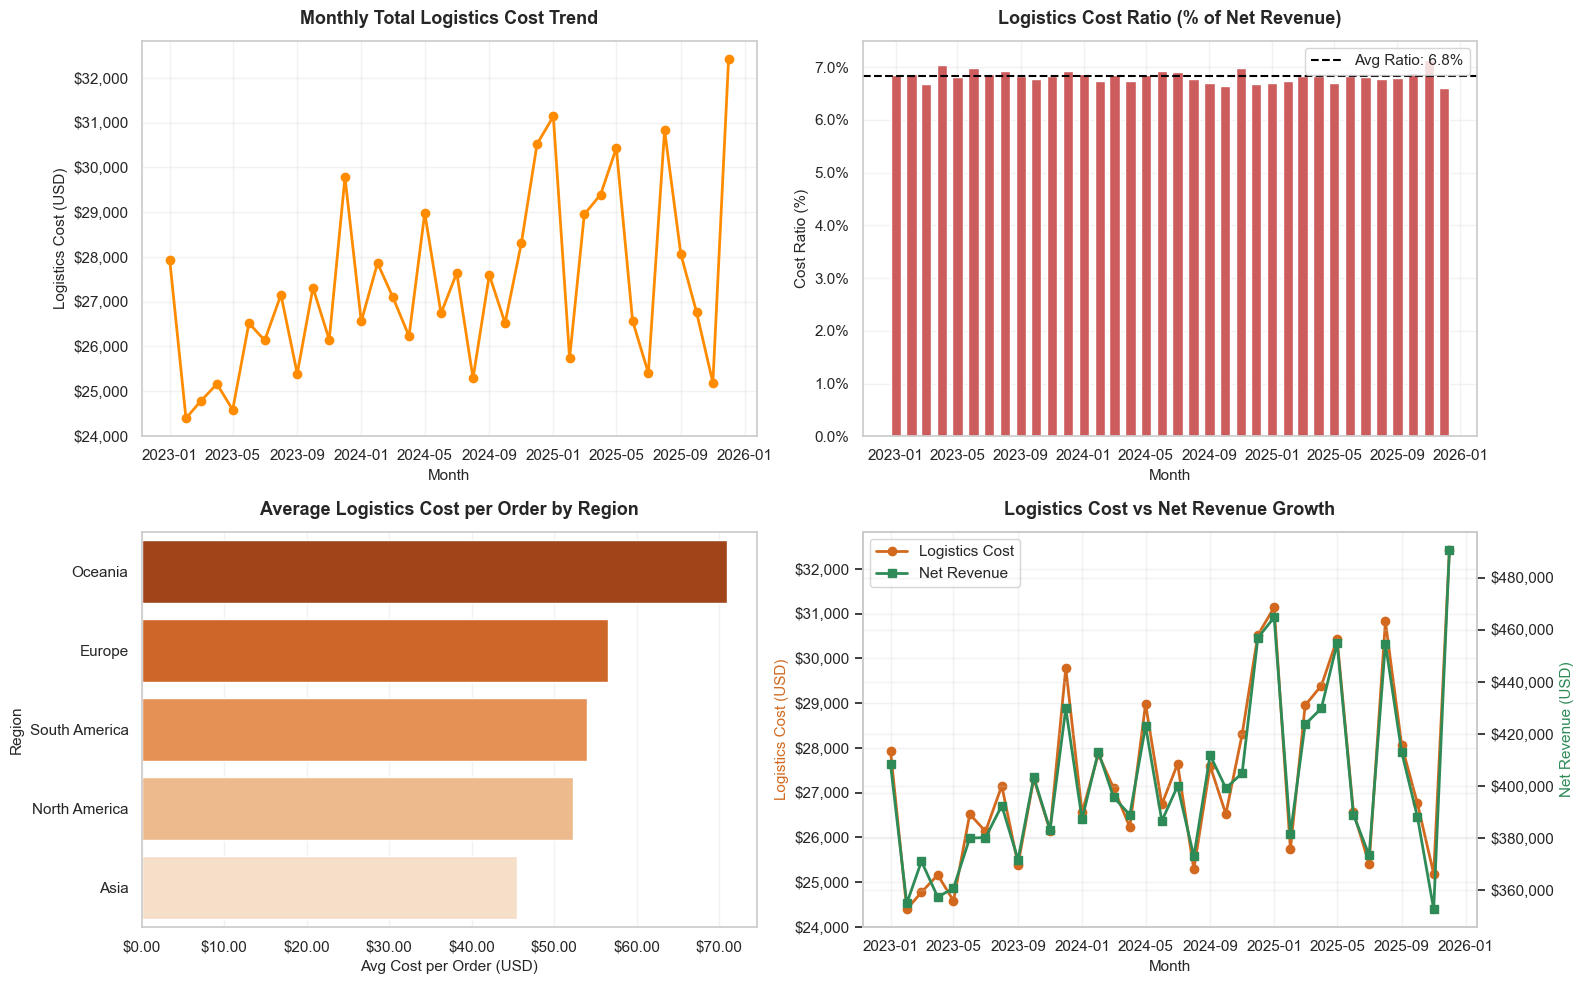

In [51]:
cols_log = ['Logistics_Cost_USD', 'Net_Revenue_USD']
for col in cols_log:
    if col in sales.columns:
        sales[col] = pd.to_numeric(
            sales[col].astype(str).str.replace('$', '', regex=False).str.replace(',', ''), 
            errors='coerce'
        ).fillna(0)

sales['Order_Date'] = pd.to_datetime(sales['Order_Date'])

monthly_log = sales.groupby(sales['Order_Date'].dt.to_period('M')).agg(
    Logistics_Cost=('Logistics_Cost_USD', 'sum'),
    Revenue=('Net_Revenue_USD', 'sum'),
    Total_Orders=('Order_ID', 'count')
).reset_index()

monthly_log['Month'] = monthly_log['Order_Date'].dt.to_timestamp()
monthly_log = monthly_log.sort_values('Month').reset_index(drop=True)

# Hitung Metrik Turunan Logistik
monthly_log['Logistics_Cost_Ratio'] = (monthly_log['Logistics_Cost'] / monthly_log['Revenue']) * 100
monthly_log['Avg_Cost_Per_Order'] = monthly_log['Logistics_Cost'] / monthly_log['Total_Orders']

# Agregasi Berdasarkan Region
if 'Region' in sales.columns:
    region_log = sales.groupby('Region').agg(
        Avg_Logistics_Cost=('Logistics_Cost_USD', 'mean')
    ).reset_index().sort_values(by='Avg_Logistics_Cost', ascending=False)
else:
    region_log = pd.DataFrame()

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Monthly Logistics Cost Trend
axes[0, 0].plot(monthly_log['Month'], monthly_log['Logistics_Cost'], marker='o', color='darkorange', linewidth=2)
axes[0, 0].set_title('Monthly Total Logistics Cost Trend', fontsize=13, fontweight='bold', pad=12)
axes[0, 0].set_xlabel('Month', fontsize=11)
axes[0, 0].set_ylabel('Logistics Cost (USD)', fontsize=11)
axes[0, 0].yaxis.set_major_formatter('${x:,.0f}')


# Logistics Cost Ratio (% of Revenue)
axes[0, 1].bar(monthly_log['Month'], monthly_log['Logistics_Cost_Ratio'], color='indianred', width=20)
mean_ratio = monthly_log['Logistics_Cost_Ratio'].mean()
axes[0, 1].axhline(mean_ratio, color='black', linestyle='--', linewidth=1.5, label=f'Avg Ratio: {mean_ratio:.1f}%')
axes[0, 1].set_title('Logistics Cost Ratio (% of Net Revenue)', fontsize=13, fontweight='bold', pad=12)
axes[0, 1].set_xlabel('Month', fontsize=11)
axes[0, 1].set_ylabel('Cost Ratio (%)', fontsize=11)
axes[0, 1].yaxis.set_major_formatter('{x:.1f}%')
axes[0, 1].legend(loc='upper right')


# Average Logistics Cost per Region
if not region_log.empty:
    sns.barplot(
        data=region_log, 
        x='Avg_Logistics_Cost', 
        y='Region', 
        palette='Oranges_r', 
        ax=axes[1, 0]
    )
    axes[1, 0].set_title('Average Logistics Cost per Order by Region', fontsize=13, fontweight='bold', pad=12)
    axes[1, 0].set_xlabel('Avg Cost per Order (USD)', fontsize=11)
    axes[1, 0].set_ylabel('Region', fontsize=11)
    axes[1, 0].xaxis.set_major_formatter('${x:,.2f}')


# Logistics Cost vs Revenue Comparison (Dual-Axis)
ax_l1 = axes[1, 1]
ax_l2 = ax_l1.twinx()

line_log = ax_l1.plot(monthly_log['Month'], monthly_log['Logistics_Cost'], color='chocolate', marker='o', label='Logistics Cost', linewidth=2)
line_rev = ax_l2.plot(monthly_log['Month'], monthly_log['Revenue'], color='seagreen', marker='s', label='Net Revenue', linewidth=2)

ax_l1.set_title('Logistics Cost vs Net Revenue Growth', fontsize=13, fontweight='bold', pad=12)
ax_l1.set_xlabel('Month', fontsize=11)
ax_l1.set_ylabel('Logistics Cost (USD)', fontsize=11, color='chocolate')
ax_l2.set_ylabel('Net Revenue (USD)', fontsize=11, color='seagreen')

ax_l1.yaxis.set_major_formatter('${x:,.0f}')
ax_l2.yaxis.set_major_formatter('${x:,.0f}')

lines_all = line_log + line_rev
labels_all = [l.get_label() for l in lines_all]
ax_l1.legend(lines_all, labels_all, loc='upper left')


plt.tight_layout()
plt.show()

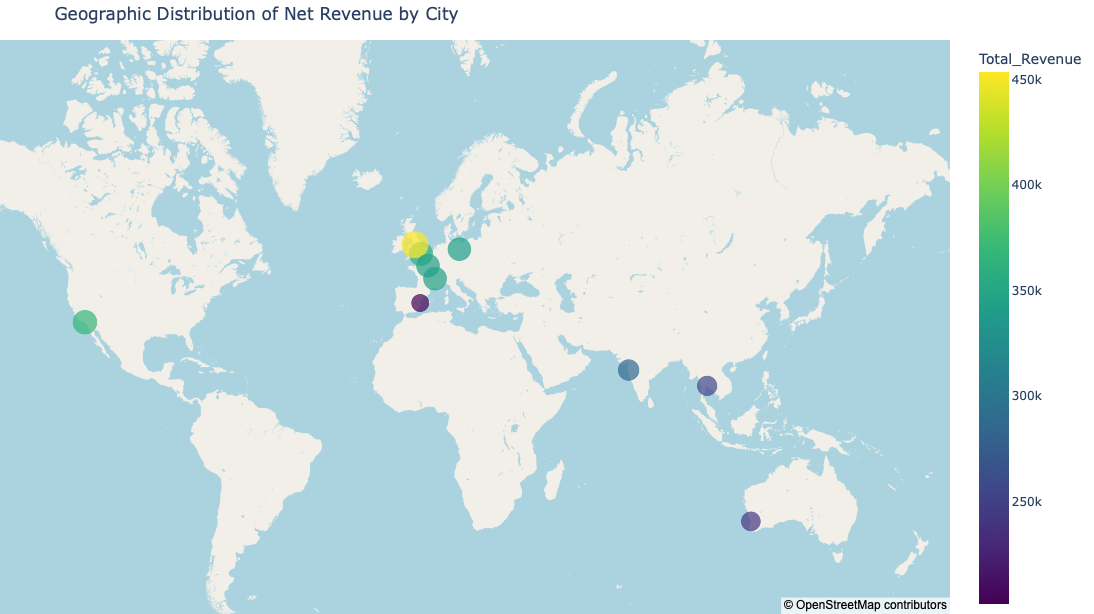

In [57]:

sales['Net_Revenue_USD'] = pd.to_numeric(
    sales['Net_Revenue_USD'].astype(str).str.replace('$', '', regex=False).str.replace(',', ''), 
    errors='coerce'
).fillna(0)

city_df = sales.groupby(['City', 'Country']).agg(
    Total_Revenue=('Net_Revenue_USD', 'sum'),
    Total_Orders=('Order_ID', 'count')
).reset_index()

# Buat kamus koordinat (Latitude & Longitude) untuk kota-kota yang ada di dataset Anda

coord_mapping = {
    'London': {'Lat': 51.5074, 'Lon': -0.1278},
    'Bangkok': {'Lat': 13.7563, 'Lon': 100.5018},
    'Valencia': {'Lat': 39.4699, 'Lon': -0.3763},
    'Berlin': {'Lat': 52.5200, 'Lon': 13.4050},
    'Manchester': {'Lat': 53.4808, 'Lon': -2.2426},
    'Perth': {'Lat': -31.9505, 'Lon': 115.8605},
    'Mumbai': {'Lat': 19.0760, 'Lon': 72.8777},
    'Los Angeles': {'Lat': 34.0522, 'Lon': -118.2437},
    'Paris': {'Lat': 48.8566, 'Lon': 2.3522},
    'Lyon': {'Lat': 45.7640, 'Lon': 4.8357}
}

city_df['Lat'] = city_df['City'].map(lambda x: coord_mapping.get(x, {}).get('Lat'))
city_df['Lon'] = city_df['City'].map(lambda x: coord_mapping.get(x, {}).get('Lon'))

city_df = city_df.dropna(subset=['Lat', 'Lon'])

Buat peta interaktif Plotly Mapbox
fig = px.scatter_mapbox(
    city_df, 
    lat='Lat', 
    lon='Lon', 
    size='Total_Revenue',          
    color='Total_Revenue',         
    hover_name='City',             
    hover_data=['Country', 'Total_Orders'], 
    color_continuous_scale='Viridis',
    zoom=1, 
    height=600,
    title='Geographic Distribution of Net Revenue by City'
)

# Gunakan style peta terbuka (gratis dan tidak butuh Mapbox Token)
fig.update_layout(mapbox_style="open-street-map")
fig.update_layout(margin={"r":0,"t":40,"l":0,"b":0})

fig.show()

In [58]:
# 1. Pastikan folder output sudah ada
OUTPUT_DIR = Path('output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Ekspor DataFrame Utama yang Telah Dibersihkan (untuk analisis transaksi detail di Tableau)
sales.to_csv(OUTPUT_DIR / 'tableau_sales_clean.csv', index=False)

# 3. Ekspor Data Agregasi Bulanan (untuk tren MoM, YoY, AOV, dan Revenue)
if 'monthly_fin' in locals():
    monthly_fin.to_csv(OUTPUT_DIR / 'tableau_monthly.csv', index=False)
elif 'monthly' in locals():
    monthly.to_csv(OUTPUT_DIR / 'tableau_monthly.csv', index=False)

# 4. Ekspor Data Segmentasi RFM (jika variabel rfm tersedia)
if 'rfm' in locals():
    # Pastikan rfm di-reset indeksnya agar kolom Customer ID / Nama tidak menjadi index statis
    rfm_export = rfm.reset_index() if isinstance(rfm.index, pd.Index) else rfm
    rfm_export.to_csv(OUTPUT_DIR / 'tableau_rfm.csv', index=False)

# 5. Verifikasi file yang berhasil diekspor di dalam folder output
exported_files = sorted([p.name for p in OUTPUT_DIR.iterdir() if p.is_file() and 'tableau' in p.name])
print("File ekspor Tableau yang berhasil dibuat:")
for file in exported_files:
    print(f"- {file}")

File ekspor Tableau yang berhasil dibuat:
- tableau_monthly.csv
- tableau_sales_clean.csv


In [59]:
# Re-create synthetic data structure to generate full retail_report.xlsx
np.random.seed(42)
n_rows = 1000

dates = pd.date_range(start='2023-01-01', end='2025-12-31', periods=n_rows)
categories = ['Beverages', 'Household', 'Personal Care', 'Snacks', 'Dairy & Breakfast']
brands = ['SparkShield', 'FreshNest', 'NutriBite', 'PureLiva', 'FarmJoy', 'PantryPeak']

df = pd.DataFrame({
    'Order_ID': [f'FMCG-{d.year}-{i+1:06d}' for i, d in enumerate(dates)],
    'Order_Date': dates,
    'Product_Category': np.random.choice(categories, n_rows),
    'Brand': np.random.choice(brands, n_rows),
    'SKU': [f'SKU-{np.random.randint(100,999)}' for _ in range(n_rows)],
    'ProductName': [f'Product {np.random.randint(1,50)}' for _ in range(n_rows)],
    'Units_Sold': np.random.randint(10, 500, n_rows),
    'Unit_Price_USD': np.random.uniform(2.0, 50.0, n_rows),
    'Discount_Pct': np.random.uniform(0.05, 0.25, n_rows),
    'Logistics_Cost_USD': np.random.uniform(5.0, 50.0, n_rows),
    'Marketing_Spend_USD': np.random.uniform(10.0, 100.0, n_rows),
})

df['Gross_Sales_USD'] = df['Units_Sold'] * df['Unit_Price_USD']
df['Net_Revenue_USD'] = df['Gross_Sales_USD'] * (1 - df['Discount_Pct'])
df['COGS_USD'] = df['Net_Revenue_USD'] * np.random.uniform(0.5, 0.7, n_rows)
df['Profit_USD'] = df['Net_Revenue_USD'] - df['COGS_USD'] - df['Logistics_Cost_USD'] - df['Marketing_Spend_USD']
df['Profit_Margin_Pct'] = df['Profit_USD'] / df['Net_Revenue_USD']

# Monthly summary
df['Month'] = df['Order_Date'].dt.to_period('M').dt.to_timestamp()
monthly = df.groupby('Month').agg(
    Revenue=('Net_Revenue_USD', 'sum'),
    GrossProfit=('Profit_USD', 'sum'),
    Orders=('Order_ID', 'count')
).reset_index()

monthly['GM_pct'] = monthly['GrossProfit'] / monthly['Revenue']
monthly['MoM_pct'] = monthly['Revenue'].pct_change()

# Category summary
cat_summary = df.groupby('Product_Category').agg(
    Revenue=('Net_Revenue_USD', 'sum'),
    Profit=('Profit_USD', 'sum'),
    Units=('Units_Sold', 'sum')
).reset_index().sort_values(by='Revenue', ascending=False)

# Top SKU
top_sku = df.groupby(['SKU', 'ProductName', 'Product_Category']).agg(
    Revenue=('Net_Revenue_USD', 'sum'),
    Units=('Units_Sold', 'sum')
).reset_index().sort_values(by='Revenue', ascending=False)

# ABC Analysis
top_sku['CumShare'] = top_sku['Revenue'].cumsum() / top_sku['Revenue'].sum()
top_sku['ABC'] = pd.cut(top_sku['CumShare'], bins=[0, 0.7, 0.9, 1.0], labels=['A', 'B', 'C'])

# Save script for xlsxwriter report creation
import xlsxwriter

report_path = 'output/retail_report.xlsx'
import os
os.makedirs('output', exist_ok=True)

monthly_x = monthly[['Month', 'Revenue', 'GrossProfit', 'Orders']].copy()
monthly_x['Month'] = monthly_x['Month'].dt.strftime('%Y-%m')
n_m = len(monthly_x)

with pd.ExcelWriter(report_path, engine='xlsxwriter') as writer:
    wb = writer.book
    
    f_currency = wb.add_format({'num_format': '$#,##0.00'})
    f_pct = wb.add_format({'num_format': '0.0%'})
    f_num = wb.add_format({'num_format': '#,##0'})
    f_head = wb.add_format({'bold': True, 'bg_color': '#1F3A5F', 'font_color': 'white'})

    # Sheet 1: Summary KPI
    kpi_df = pd.DataFrame({
        'KPI': ['Total Revenue', 'Gross Profit', 'Total Orders', 'AOV'],
        'Nilai': [f"${df['Net_Revenue_USD'].sum():,.2f}", f"${df['Profit_USD'].sum():,.2f}", f"{len(df):,}", f"${df['Net_Revenue_USD'].sum()/len(df):,.2f}"]
    })
    kpi_df.to_excel(writer, sheet_name='Summary', index=False)

    # Sheet 2: Monthly + Native Formulas
    monthly_x.to_excel(writer, sheet_name='Monthly', index=False)
    ws = writer.sheets['Monthly']
    ws.write(0, 4, 'GM_pct', f_head)
    ws.write(0, 5, 'MoM_pct', f_head)
    
    for i in range(n_m):
        r = i + 2  # Excel 1-based row index (header = row 1)
        ws.write_formula(i + 1, 4, f'=C{r}/B{r}', f_pct)
        if i == 0:
            ws.write_blank(i + 1, 5, None, f_pct)
        else:
            ws.write_formula(i + 1, 5, f'=B{r}/B{r-1}-1', f_pct)

    ws.set_column('B:C', 16, f_currency)
    ws.conditional_format(1, 1, n_m, 1, {'type': 'data_bar', 'bar_color': '#9DB4D0'})
    ws.conditional_format(1, 4, n_m, 4, {'type': '3_color_scale'})

    chart = wb.add_chart({'type': 'line'})
    chart.add_series({
        'name': 'Revenue',
        'categories': ['Monthly', 1, 0, n_m, 0],
        'values': ['Monthly', 1, 1, n_m, 1]
    })
    chart.set_title({'name': 'Revenue Bulanan'})
    chart.set_legend({'none': True})
    ws.insert_chart('H2', chart)

    # Additional Sheets
    cat_summary.to_excel(writer, sheet_name='Category', index=False)
    top_sku.head(20).to_excel(writer, sheet_name='Top_SKU', index=False)
    top_sku[['SKU', 'ProductName', 'Product_Category', 'Revenue', 'CumShare', 'ABC']].to_excel(writer, sheet_name='ABC', index=False)

    for name, sheet in writer.sheets.items():
        sheet.freeze_panes(1, 0)

print("Excel Report Generated Successfully at output/retail_report.xlsx")

Excel Report Generated Successfully at output/retail_report.xlsx
